('results_plot.png', 'results_plot.pdf')

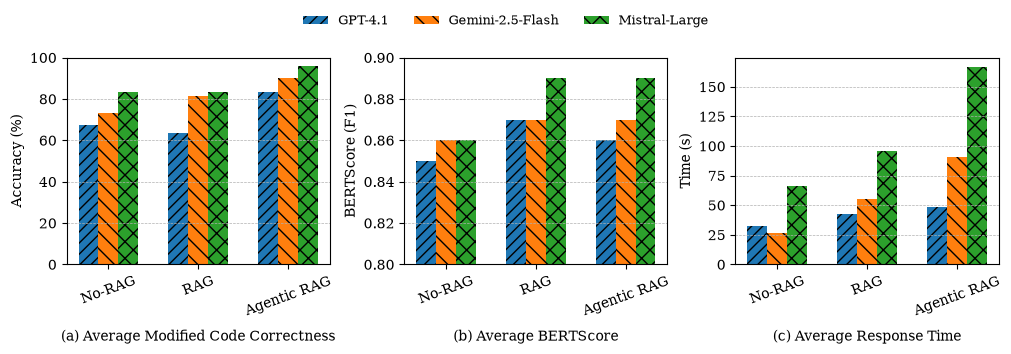

In [7]:
import matplotlib.pyplot as plt
import numpy as np

# Data
methods = ["No-RAG", "RAG", "Agentic RAG"]
models = ["GPT-4.1", "Gemini-2.5-Flash", "Mistral-Large"]

time = np.array([
    [32.54, 26.52, 66.06],
    [42.30, 55.61, 95.48],
    [48.28, 90.57, 166.32],
])

accuracy = np.array([
    [67.4, 73.4, 83.4],
    [63.4, 81.4, 83.4],
    [83.4, 90.0, 96.0],
])

bert = np.array([
    [0.85, 0.86, 0.86],
    [0.87, 0.87, 0.89],
    [0.86, 0.87, 0.89],
])
bert = np.round(bert, 2)

x = np.arange(len(methods))
width = 0.22

# IEEE-style font
plt.rc("font", family="serif", size=10)
plt.rc("axes", titlesize=10, labelsize=10)
plt.rc("legend", fontsize=9)

fig, axes = plt.subplots(1, 3, figsize=(10, 3), constrained_layout=True)

hatches = ["///", "\\\\", "xx"]

# === Subplot B: Accuracy ===
ax = axes[0]
for i, model in enumerate(models):
    ax.bar(x + (i - 1) * width, accuracy[:, i], width, label=model, hatch=hatches[i])
ax.set_xticks(x)
ax.set_xticklabels(methods, rotation=20)
ax.set_ylabel("Accuracy (%)")
ax.set_ylim(0, 100)
ax.grid(axis="y", linestyle="--", linewidth=0.5)

ax.text(0.5, -0.35, "(a) Average Modified Code Correctness", ha="center", va="center", transform=ax.transAxes)

# === Subplot A: Time ===
ax = axes[2]
for i, model in enumerate(models):
    ax.bar(x + (i - 1) * width, time[:, i], width, label=model, hatch=hatches[i])
ax.set_xticks(x)
ax.set_xticklabels(methods, rotation=20)
ax.set_ylabel("Time (s)")
ax.grid(axis="y", linestyle="--", linewidth=0.5)

# Add subplot label below
ax.text(0.5, -0.35, "(c) Average Response Time", ha="center", va="center", transform=ax.transAxes)

# === Subplot C: BERTScore ===
ax = axes[1]
for i, model in enumerate(models):
    ax.bar(x + (i - 1) * width, bert[:, i], width, label=model, hatch=hatches[i])
ax.set_xticks(x)
ax.set_xticklabels(methods, rotation=20)
ax.set_ylabel("BERTScore (F1)")
ax.set_ylim(0.8, 0.9)
ax.grid(axis="y", linestyle="--", linewidth=0.5)

ax.text(0.5, -0.35, "(b) Average BERTScore", ha="center", va="center", transform=ax.transAxes)

# Only one legend for the whole figure
fig.legend(models, loc="upper center", ncol=3, frameon=False, bbox_to_anchor=(0.5, 1.15))

png_path = "results_plot.png"
pdf_path = "results_plot.pdf"
fig.savefig(png_path, bbox_inches="tight")
fig.savefig(pdf_path, bbox_inches="tight")

png_path, pdf_path


In [5]:
fig, ax = plt.subplots(figsize=(4, 3), constrained_layout=True)

for i, model in enumerate(models):
    ax.bar(
        x + (i - 1) * width,
        accuracy[:, i],
        width,
        label=model,
        hatch=hatches[i]
    )

ax.set_xticks(x)
ax.set_xticklabels(methods, rotation=20)
ax.set_ylabel("Accuracy")
ax.set_ylim(0, 1)
ax.grid(axis="y", linestyle="--", linewidth=0.5)

ax.legend(
    title="Models",
    loc="lower center",
    bbox_to_anchor=(0.5, 1.02),
    ncol=3,
    frameon=False
)

# ---- High-quality saving ----
fig.savefig("accuracy_plot.png", dpi=600, bbox_inches="tight")
fig.savefig("accuracy_plot.pdf", bbox_inches="tight")

plt.close(fig)
